# ENG 2440 Assignment 2: Tumor Segmentation in MRI Volumes

Whole-tumor segmentation of multimodal 3D brain MRI (MSD Task01_BrainTumour).

## 0. Setup

### 0.1 Imports and settings

In [1]:
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.colors import ListedColormap
from scipy import ndimage
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

DATA_ROOT = Path("Task01_BrainTumour")
SPLIT_FILE = Path("assignment2_split.csv")

CACHE_DIR = Path("cache")                        # preprocessed volumes (.npy)
FIGURES_DIR = Path("outputs/figures")
RESULTS_DIR = Path("outputs/results")            # tables (.csv)
CHECKPOINTS_DIR = Path("outputs/checkpoints")    # model weights (.pt)
for folder in [CACHE_DIR, FIGURES_DIR, RESULTS_DIR, CHECKPOINTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

MODALITIES = ["FLAIR", "T1w", "T1gd", "T2w"]     # channel order in every image file (dataset.json)
SEED = 42

# Training
PATCH_SIZE = (64, 64, 64)    # voxels; must divide by 16 because the U-Net halves it 4 times
BATCH_SIZE = 8               # patches per training step
LEARNING_RATE = 3e-4         # Adam, constant
EPOCHS = 30                  # validation runs once per epoch
STEPS_PER_EPOCH = 500        # training steps per epoch
TUMOR_PROBABILITY = 0.5      # tumor-aware sampler: chance that a patch is centred on a tumor voxel

# Inference
OVERLAP = 0.5                # fraction of a patch shared with the next one in sliding-window inference
THRESHOLD = 0.5              # tumor if probability > 0.5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True     # pick the fastest convolution algorithm for our fixed patch size

pd.set_option("display.max_rows", 100)     # show all 73 per-case rows of a split

# One row per case: split name and image/label paths
split_df = pd.read_csv(SPLIT_FILE, index_col="case_id")

### 0.2 Helper functions

#### Loading

In [2]:
def set_seed(seed=SEED):
    """Seed Python, NumPy and PyTorch so a run can be repeated."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def ids_in_split(split):
    return list(split_df.index[split_df["split"] == split])


def load_case(case_id):
    """Original image (X, Y, Z, 4), label (X, Y, Z) with values 0-3, affine and voxel spacing in mm."""
    row = split_df.loc[case_id]
    # Reorder the axes to RAS (X: left -> right, Y: back -> front, Z: down -> up)
    image_file = nib.as_closest_canonical(nib.load(DATA_ROOT / row.image_relpath))
    label_file = nib.as_closest_canonical(nib.load(DATA_ROOT / row.label_relpath))
    image = image_file.get_fdata(dtype=np.float32)
    label = np.asarray(label_file.dataobj, dtype=np.uint8)
    return image, label, image_file.affine, label_file.header.get_zooms()[:3]


def get_spacing(case_id):
    """Voxel size in mm, read from the label header."""
    return nib.load(DATA_ROOT / split_df.loc[case_id, "label_relpath"]).header.get_zooms()[:3]


def load_preprocessed_case(case_id):
    """Case saved in Section C: image (4, X, Y, Z) float16 and label (X, Y, Z) uint8."""
    image = np.load(CACHE_DIR / f"{case_id}_image.npy")
    label = np.load(CACHE_DIR / f"{case_id}_label.npy")
    return image, label


def load_model(sampling):
    """Best weights (highest validation Dice) of the "uniform" or "tumor" run."""
    model = UNet3D().to(device)
    model.load_state_dict(torch.load(CHECKPOINTS_DIR / f"{sampling}_best.pt"))
    return model

#### Patches

In [3]:
def augment(image, mask, rng, flip_chance=0.5):
    """Random left-right flip and per-channel brightness scaling of one patch."""
    # Flip image and mask together along X so they stay aligned
    if rng.random() < flip_chance:
        image = np.flip(image, axis=1)
        mask = np.flip(mask, axis=0)

    # Multiply each channel by a random factor in [0.9, 1.1]; the zero background stays zero
    image = image * rng.uniform(0.9, 1.1, size=(4, 1, 1, 1)).astype(np.float32)

    # np.flip gives a reversed view, but PyTorch needs a normal (contiguous) array
    return np.ascontiguousarray(image), np.ascontiguousarray(mask)


class PatchDataset(Dataset):
    """Random training patches: image [4, 64, 64, 64] and tumor mask [1, 64, 64, 64].

    "uniform": the patch can be anywhere in the volume with equal chance.
    "tumor":   with chance TUMOR_PROBABILITY the patch is centred on a random tumor voxel.
    """

    def __init__(self, cases, sampling, length):
        self.cases = cases            # list of (image, label) pairs
        self.sampling = sampling
        self.length = length          # patches per epoch
        self.rng = np.random.default_rng(SEED)
        # Coordinates of every tumor voxel, so the tumor-aware sampler can pick one quickly
        self.tumor_voxels = [np.argwhere(label > 0).astype(np.int16) for _, label in cases]

    def __len__(self):
        return self.length

    def __getitem__(self, index):
        # The index is ignored: each call picks a random case and a random position
        case = self.rng.integers(len(self.cases))
        image, label = self.cases[case]
        size = np.array(PATCH_SIZE)
        last_corner = np.array(label.shape) - size     # largest corner that keeps the patch inside

        if self.sampling == "tumor" and self.rng.random() < TUMOR_PROBABILITY:
            center = self.tumor_voxels[case][self.rng.integers(len(self.tumor_voxels[case]))]
            corner = np.clip(center - size // 2, 0, last_corner)
        else:
            corner = self.rng.integers(0, last_corner + 1)

        x, y, z = corner
        dx, dy, dz = PATCH_SIZE
        image_patch = image[:, x:x + dx, y:y + dy, z:z + dz].astype(np.float32)
        mask_patch = label[x:x + dx, y:y + dy, z:z + dz] > 0      # whole tumor = any label above 0

        image_patch, mask_patch = augment(image_patch, mask_patch, self.rng)
        return torch.from_numpy(image_patch), torch.from_numpy(mask_patch[None].astype(np.float32))

#### Model and loss

In [4]:
def conv_block(in_channels, out_channels):
    """Two 3x3x3 convolutions, each followed by instance normalisation and leaky ReLU."""
    return nn.Sequential(
        nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.InstanceNorm3d(out_channels, affine=True),
        nn.LeakyReLU(0.01, inplace=True),
        nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.InstanceNorm3d(out_channels, affine=True),
        nn.LeakyReLU(0.01, inplace=True),
    )


class UNet3D(nn.Module):
    """3D U-Net. Input [N, 4, D, H, W] MRI, output [N, 1, D, H, W] tumor logits."""

    def __init__(self, in_channels=4, out_channels=1):
        super().__init__()
        # Encoder: channels double at each level, max pooling halves the size
        self.enc1 = conv_block(in_channels, 16)
        self.enc2 = conv_block(16, 32)
        self.enc3 = conv_block(32, 64)
        self.enc4 = conv_block(64, 128)
        self.bottom = conv_block(128, 256)
        self.pool = nn.MaxPool3d(2)

        # Decoder: upsample x2, then join with the encoder output of the same size (skip connection)
        self.up4 = nn.ConvTranspose3d(256, 128, kernel_size=2, stride=2)
        self.dec4 = conv_block(256, 128)
        self.up3 = nn.ConvTranspose3d(128, 64, kernel_size=2, stride=2)
        self.dec3 = conv_block(128, 64)
        self.up2 = nn.ConvTranspose3d(64, 32, kernel_size=2, stride=2)
        self.dec2 = conv_block(64, 32)
        self.up1 = nn.ConvTranspose3d(32, 16, kernel_size=2, stride=2)
        self.dec1 = conv_block(32, 16)

        self.out = nn.Conv3d(16, out_channels, kernel_size=1)   # one tumor logit per voxel

    def forward(self, x):
        e1 = self.enc1(x)                        # 64^3
        e2 = self.enc2(self.pool(e1))            # 32^3
        e3 = self.enc3(self.pool(e2))            # 16^3
        e4 = self.enc4(self.pool(e3))            # 8^3
        bottom = self.bottom(self.pool(e4))      # 4^3

        d4 = self.dec4(torch.cat([self.up4(bottom), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)


def dice_bce_loss(probabilities, target):
    """Binary cross-entropy + (1 - soft Dice). Inputs: [N, 1, D, H, W] with values in [0, 1]."""
    bce = F.binary_cross_entropy(probabilities.clamp(1e-6, 1 - 1e-6), target)   # clamp avoids log(0)

    # Soft Dice per patch; +1 keeps it defined for patches without tumor
    overlap = (probabilities * target).sum(dim=(1, 2, 3, 4))
    total = probabilities.sum(dim=(1, 2, 3, 4)) + target.sum(dim=(1, 2, 3, 4))
    soft_dice = (2 * overlap + 1) / (total + 1)
    return bce + 1 - soft_dice.mean()

#### Prediction

In [5]:
def patch_starts(volume_size, patch_size, overlap):
    """Start positions of overlapping patches along one axis; the last patch ends at the border."""
    step = int(patch_size * (1 - overlap))
    starts = list(range(0, volume_size - patch_size + 1, step))
    if starts[-1] != volume_size - patch_size:
        starts.append(volume_size - patch_size)
    return starts


@torch.no_grad()
def predict_volume(model, image, overlap=OVERLAP):
    """Sliding-window inference: tumor probability (X, Y, Z) for a preprocessed image (4, X, Y, Z).

    Overlapping patch probabilities are averaged, before any thresholding.
    """
    model.eval()
    image = torch.from_numpy(image).float().to(device)
    shape = image.shape[1:]
    dx, dy, dz = PATCH_SIZE
    probability_sum = torch.zeros(shape, device=device)
    patch_count = torch.zeros(shape, device=device)      # how many patches covered each voxel

    for x in patch_starts(shape[0], dx, overlap):
        for y in patch_starts(shape[1], dy, overlap):
            for z in patch_starts(shape[2], dz, overlap):
                patch = image[None, :, x:x + dx, y:y + dy, z:z + dz]    # None adds the batch axis
                with torch.autocast(device_type=device.type, dtype=torch.bfloat16):
                    logits = model(patch)
                probability_sum[x:x + dx, y:y + dy, z:z + dz] += torch.sigmoid(logits.float())[0, 0]
                patch_count[x:x + dx, y:y + dy, z:z + dz] += 1

    return probability_sum / patch_count


def keep_largest_component(mask):
    """Postprocessing: keep only the largest connected tumor region (26-connectivity)."""
    regions, count = ndimage.label(mask, structure=np.ones((3, 3, 3)))
    if count <= 1:
        return mask
    sizes = np.bincount(regions.ravel())[1:]       # voxels per region, background (0) skipped
    return regions == np.argmax(sizes) + 1


def predict_mask(model, image, postprocess=False, overlap=OVERLAP):
    """Binary tumor mask (numpy bool) for a preprocessed image."""
    mask = (predict_volume(model, image, overlap) > THRESHOLD).cpu().numpy()
    return keep_largest_component(mask) if postprocess else mask

#### Training

In [6]:
@torch.no_grad()
def validate(model, case_ids):
    """Mean full-volume loss and Dice. Cases are read from the cache one at a time to save memory."""
    losses, dices = [], []
    for case_id in case_ids:
        image, label = load_preprocessed_case(case_id)
        probabilities = predict_volume(model, image)
        target = torch.from_numpy(label > 0).float().to(device)
        losses.append(dice_bce_loss(probabilities[None, None], target[None, None]).item())
        dices.append(dice_score((probabilities > THRESHOLD).cpu().numpy(), label > 0))
    return np.mean(losses), np.mean(dices)


def train_model(sampling, train_cases, val_ids):
    """Train a new U-Net with the "uniform" or "tumor" sampler. Returns the model and its history table.

    The seed is reset first, so both samplers start from the same weights. The history and
    the best weights (highest validation Dice) are saved after every epoch.
    """
    set_seed()
    model = UNet3D().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    dataset = PatchDataset(train_cases, sampling, length=STEPS_PER_EPOCH * BATCH_SIZE)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, pin_memory=True)

    history = []
    for epoch in range(1, EPOCHS + 1):
        start_time = time.time()
        model.train()
        losses, tumor_patches = [], 0

        for images, masks in tqdm(loader, desc=f"{sampling} epoch {epoch}", leave=False):
            images, masks = images.to(device), masks.to(device)
            # Forward pass in bfloat16 for speed, loss in float32
            with torch.autocast(device_type=device.type, dtype=torch.bfloat16):
                logits = model(images)
            loss = dice_bce_loss(torch.sigmoid(logits.float()), masks)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            losses.append(loss.item())
            tumor_patches += (masks.sum(dim=(1, 2, 3, 4)) > 0).sum().item()   # patches with any tumor

        val_loss, val_dice = validate(model, val_ids)
        history.append({"epoch": epoch, "train_loss": np.mean(losses), "val_loss": val_loss,
                        "val_dice": val_dice, "tumor_patch_fraction": tumor_patches / len(dataset),
                        "minutes": (time.time() - start_time) / 60})
        print(f"epoch {epoch:2d}: train loss {np.mean(losses):.3f}, val loss {val_loss:.3f}, "
              f"val Dice {val_dice:.3f}, tumor patches {tumor_patches / len(dataset):.2f}")

        save_table(pd.DataFrame(history), f"{sampling}_history")
        if val_dice == max(row["val_dice"] for row in history):
            torch.save(model.state_dict(), CHECKPOINTS_DIR / f"{sampling}_best.pt")

    return model, pd.DataFrame(history)

#### Metrics

In [7]:
def dice_score(pred, target):
    """2 |A and B| / (|A| + |B|) for boolean masks; 1 when both are empty."""
    total = pred.sum() + target.sum()
    return 1.0 if total == 0 else 2 * (pred & target).sum() / total


def hd95_mm(pred, target, spacing):
    """95th percentile Hausdorff distance between the two mask surfaces in mm (NaN if a mask is empty)."""
    if not pred.any() or not target.any():
        return np.nan
    # Surface = mask voxels that disappear after one erosion step
    pred_surface = pred & ~ndimage.binary_erosion(pred)
    target_surface = target & ~ndimage.binary_erosion(target)
    # Distance in mm from every voxel to the nearest surface voxel of each mask
    distance_to_target = ndimage.distance_transform_edt(~target_surface, sampling=spacing)
    distance_to_pred = ndimage.distance_transform_edt(~pred_surface, sampling=spacing)
    return max(np.percentile(distance_to_target[pred_surface], 95),
               np.percentile(distance_to_pred[target_surface], 95))


def evaluate_case(pred, target, spacing):
    """All whole-tumor metrics for one case as a dict (one table row)."""
    voxel_ml = np.prod(spacing) / 1000              # 1 mL = 1000 mm^3
    pred_ml = pred.sum() * voxel_ml
    true_ml = target.sum() * voxel_ml
    return {
        "dice": dice_score(pred, target),
        "iou": (pred & target).sum() / (pred | target).sum(),
        "sensitivity": (pred & target).sum() / target.sum(),
        "hd95_mm": hd95_mm(pred, target, spacing),
        "true_volume_ml": true_ml,
        "pred_volume_ml": pred_ml,
        "volume_error_ml": pred_ml - true_ml,                 # > 0 means too much tumor predicted
        "volume_error_pct": 100 * (pred_ml - true_ml) / true_ml,
        "fp_volume_ml": (pred & ~target).sum() * voxel_ml,    # predicted tumor outside the reference
        "empty_prediction": not pred.any(),
    }


def evaluate_model(model, case_ids, postprocess=False, overlap=OVERLAP, zero_channel=None):
    """Predict every case with sliding windows; returns one row of metrics per case.

    zero_channel: index of an MRI channel to replace with zeros (bonus 1), or None.
    """
    rows = {}
    for case_id in tqdm(case_ids, desc="evaluating", leave=False):
        image, label = load_preprocessed_case(case_id)
        if zero_channel is not None:
            image[zero_channel] = 0
        prediction = predict_mask(model, image, postprocess, overlap)
        rows[case_id] = evaluate_case(prediction, label > 0, get_spacing(case_id))
    return pd.DataFrame.from_dict(rows, orient="index")

#### Saving and plotting

In [8]:
def save_table(table, name):
    """Save to outputs/results/<name>.csv and return the table so it also shows in the notebook."""
    table.to_csv(RESULTS_DIR / f"{name}.csv")
    return table


def save_figure(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def get_plane_slice(volume, plane, index):
    """2D slice of a RAS volume, transposed so that with origin="lower" front/top points up."""
    if plane == "axial":
        return volume[:, :, index].T
    if plane == "coronal":
        return volume[:, index, :].T
    return volume[index, :, :].T


def show_planes(image, point, overlays=(), title=None):
    """Axial, coronal and sagittal slices through voxel point=(x, y, z), with (mask, colour) overlays."""
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, plane, index in zip(axes, ["axial", "coronal", "sagittal"], [point[2], point[1], point[0]]):
        ax.imshow(get_plane_slice(image, plane, index), cmap="gray", origin="lower")
        for mask, colour in overlays:
            mask_slice = get_plane_slice(mask, plane, index)
            # Masked voxels are transparent, so only the mask itself gets coloured
            ax.imshow(np.ma.masked_where(~mask_slice, mask_slice), cmap=ListedColormap([colour]),
                      alpha=0.5, origin="lower", interpolation="none")
        ax.set_title(f"{plane} (slice {index})")
        ax.axis("off")
    fig.suptitle(title)
    return fig


def error_overlays(pred, target):
    """Overlays for show_planes: true positives green, false positives red, false negatives blue."""
    return [(pred & target, "lime"), (pred & ~target, "red"), (~pred & target, "dodgerblue")]


def plot_training_curves(history, title):
    fig, (loss_ax, dice_ax) = plt.subplots(1, 2, figsize=(11, 4))
    loss_ax.plot(history["epoch"], history["train_loss"], label="train")
    loss_ax.plot(history["epoch"], history["val_loss"], label="validation")
    loss_ax.set(xlabel="epoch", ylabel="loss")
    loss_ax.legend()
    dice_ax.plot(history["epoch"], history["val_dice"])
    dice_ax.set(xlabel="epoch", ylabel="validation Dice", ylim=(0, 1))
    fig.suptitle(title)
    return fig

### 0.3 Setup check

In [9]:
# Checks from the assignment brief
assert len(split_df) == 484
assert set(split_df["split"]) == {"train", "validation", "test"}
for row in split_df.itertuples():
    assert (DATA_ROOT / row.image_relpath).exists()
    assert (DATA_ROOT / row.label_relpath).exists()
print(split_df["split"].value_counts())

set_seed()
print("device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu")

split
train         338
test           73
validation     73
Name: count, dtype: int64
device: NVIDIA GeForce RTX 5060 Ti


## A. Define the task and inspect the volumes

### A.1 Task definition

- **Input:** 4-channel 3D MRI. **Output:** binary whole-tumor mask (labels 1–3 → 1).
- **Voxel** = 1 mm³ cube, **slice** = 2D plane, **volume** = 3D image, **case** = one patient (unit of analysis).
- Research use only; labels are not pathology-confirmed.

### A.2 Geometry of three cases

In [10]:
# Training cases only, so the test labels stay unused until Section F
inspect_ids = ids_in_split("train")[:3]

rows = {}
for case_id in inspect_ids:
    image_file = nib.load(DATA_ROOT / split_df.loc[case_id, "image_relpath"])    # raw file, not reoriented
    label_file = nib.load(DATA_ROOT / split_df.loc[case_id, "label_relpath"])
    rows[case_id] = {
        "image_shape": image_file.shape,
        "channel_order": ", ".join(MODALITIES),
        "orientation": "".join(nib.aff2axcodes(image_file.affine)),
        "voxel_spacing_mm": tuple(float(s) for s in image_file.header.get_zooms()[:3]),
        "label_shape": label_file.shape,
        "label_values": np.unique(np.asarray(label_file.dataobj)).tolist(),
    }
    print(f"{case_id} affine:\n{image_file.affine}\n")

save_table(pd.DataFrame.from_dict(rows, orient="index"), "A_case_geometry")

BRATS_001 affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]



BRATS_003 affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

BRATS_004 affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]



,image_shape,channel_order,orientation,voxel_spacing_mm,label_shape,label_values
BRATS_001,"(240, 240, 155, 4)","FLAIR, T1w, T1gd, T2w",RAS,"(1.0, 1.0, 1.0)","(240, 240, 155)","[0, 1, 2, 3]"
BRATS_003,"(240, 240, 155, 4)","FLAIR, T1w, T1gd, T2w",RAS,"(1.0, 1.0, 1.0)","(240, 240, 155)","[0, 1, 2, 3]"
BRATS_004,"(240, 240, 155, 4)","FLAIR, T1w, T1gd, T2w",RAS,"(1.0, 1.0, 1.0)","(240, 240, 155)","[0, 1, 2, 3]"


### A.3 Four modalities at the same physical location

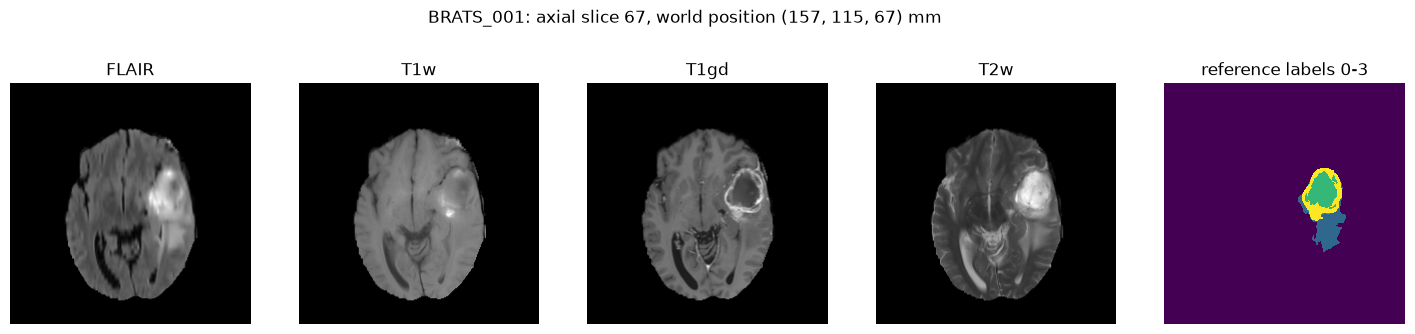

In [11]:
case_id = inspect_ids[0]
image, label, affine, spacing = load_case(case_id)

# Tumor centre as a voxel index and as a world position in mm
x, y, z = np.argwhere(label > 0).mean(axis=0).astype(int)
world = affine @ [x, y, z, 1]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for channel, name in enumerate(MODALITIES):
    axes[channel].imshow(get_plane_slice(image[..., channel], "axial", z), cmap="gray", origin="lower")
    axes[channel].set_title(name)
axes[4].imshow(get_plane_slice(label, "axial", z), vmin=0, vmax=3, origin="lower", interpolation="none")
axes[4].set_title("reference labels 0-3")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"{case_id}: axial slice {z}, world position ({world[0]:.0f}, {world[1]:.0f}, {world[2]:.0f}) mm")
save_figure(fig, "A_four_modalities")

### A.4 Reference mask in three planes

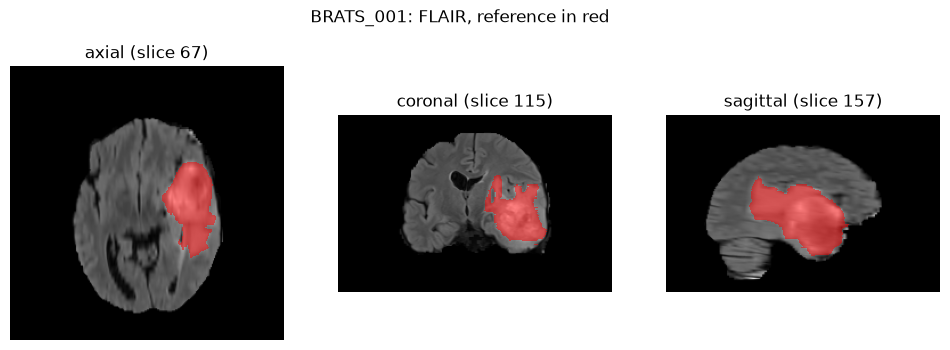

In [12]:
fig = show_planes(image[..., 0], (x, y, z), [(label > 0, "red")], title=f"{case_id}: FLAIR, reference in red")
save_figure(fig, "A_three_planes")

Indices are only array positions; the affine gives mm position and direction. Axis order, flips or spacing can differ between files, so the code reorients to RAS.

## B. Reproducible case-level split

In [13]:
# Every listed file was found in 0.3. Here: no case id may appear in two splits.
train_set = set(ids_in_split("train"))
val_set = set(ids_in_split("validation"))
test_set = set(ids_in_split("test"))
assert not (train_set & val_set) and not (train_set & test_set) and not (val_set & test_set)
print("Splits are disjoint.")
print(split_df["split"].value_counts())

Splits are disjoint.
split
train         338
test           73
validation     73
Name: count, dtype: int64


reading labels:   0%|          | 0/484 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,73.0,107.388128,66.278035,10.101,54.356003,89.113004,157.749007,318.345015
train,338.0,102.964055,56.960261,8.478,60.023003,95.484505,143.920757,265.254013
validation,73.0,100.764840,62.950126,7.285,51.853002,91.560004,148.062007,266.936013


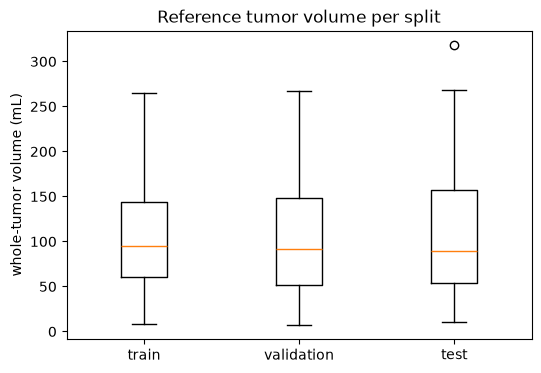

In [14]:
# Reference whole-tumor volume of every case in mL
tumor_volume = {}
for case_id in tqdm(split_df.index, desc="reading labels"):
    label_file = nib.load(DATA_ROOT / split_df.loc[case_id, "label_relpath"])
    voxel_ml = np.prod(label_file.header.get_zooms()[:3]) / 1000
    tumor_volume[case_id] = (np.asarray(label_file.dataobj) > 0).sum() * voxel_ml
tumor_volume = pd.Series(tumor_volume)

volume_summary = tumor_volume.groupby(split_df["split"]).describe()
display(save_table(volume_summary, "B_tumor_volume_by_split"))

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([tumor_volume[ids_in_split(s)] for s in ["train", "validation", "test"]],
           tick_labels=["train", "validation", "test"])
ax.set(ylabel="whole-tumor volume (mL)", title="Reference tumor volume per split")
save_figure(fig, "B_tumor_volume_by_split")

## C. Safe preprocessing of MRI and labels

### C.1 Geometry check for all cases

In [15]:
rows = {}
for case_id in tqdm(split_df.index, desc="reading headers"):
    # nib.load only reads the header here, so this is fast
    image_file = nib.load(DATA_ROOT / split_df.loc[case_id, "image_relpath"])
    label_file = nib.load(DATA_ROOT / split_df.loc[case_id, "label_relpath"])
    rows[case_id] = {
        "shape": image_file.shape,
        "spacing_mm": tuple(float(s) for s in image_file.header.get_zooms()[:3]),
        "orientation": "".join(nib.aff2axcodes(image_file.affine)),
        # The 4 channels share one file and one affine; the label must have the same grid
        "label_matches": label_file.shape == image_file.shape[:3]
                         and np.allclose(label_file.affine, image_file.affine),
    }
geometry = save_table(pd.DataFrame.from_dict(rows, orient="index"), "C_geometry")
assert geometry["label_matches"].all()
geometry[["shape", "spacing_mm", "orientation"]].value_counts()

reading headers:   0%|          | 0/484 [00:00<?, ?it/s]

shape               spacing_mm       orientation
(240, 240, 155, 4)  (1.0, 1.0, 1.0)  RAS            484
Name: count, dtype: int64

No resampling needed: all cases share one 1 mm RAS grid. Nearest-neighbour keeps labels valid; linear does not.

### C.2 Interpolation: linear for MRI, nearest-neighbour for labels

In [16]:
# Demonstration: resample the case from A to 2 mm voxels (zoom factor 0.5)
flair_linear = ndimage.zoom(image[..., 0], 0.5, order=1)                   # order=1: linear
label_nearest = ndimage.zoom(label, 0.5, order=0)                          # order=0: nearest neighbour
label_linear = ndimage.zoom(label.astype(np.float32), 0.5, order=1)        # wrong on purpose

print("FLAIR shape:", image.shape[:3], "->", flair_linear.shape)
print("original label values:", np.unique(label))
print("nearest-neighbour label values:", np.unique(label_nearest))
print("linear label values:", len(np.unique(label_linear)), "different values, e.g.", np.unique(label_linear)[1:4])

FLAIR shape: (240, 240, 155) -> (120, 120, 78)
original label values: [0 1 2 3]
nearest-neighbour label values: [0 1 2 3]
linear label values: 1970 different values, e.g. [0.08897677 0.08975355 0.0903891 ]


### C.3 Normalise, crop, pad and cache every case

In [17]:
def preprocess_case(case_id):
    """Normalise, crop to the brain, pad to at least one patch, and save to the cache."""
    image, label, affine, spacing = load_case(case_id)
    brain = np.any(image != 0, axis=-1)     # background is exactly 0 in every channel

    # Z-score each channel with the mean and std of brain voxels only
    stats = {}
    for channel, name in enumerate(MODALITIES):
        values = image[..., channel]        # a view: changes go straight into image
        values[brain] = (values[brain] - values[brain].mean()) / values[brain].std()
        stats[f"{name}_mean"] = values[brain].mean()
        stats[f"{name}_std"] = values[brain].std()

    # Crop to the smallest box that contains the brain
    brain_voxels = np.argwhere(brain)
    x0, y0, z0 = brain_voxels.min(axis=0)
    x1, y1, z1 = brain_voxels.max(axis=0) + 1
    tumor_voxels = (label > 0).sum()
    image = image[x0:x1, y0:y1, z0:z1]
    label = label[x0:x1, y0:y1, z0:z1]
    assert (label > 0).sum() == tumor_voxels, "the crop must not cut away tumor"

    # Pad with zeros at the end of any axis shorter than one patch
    padding = [(0, max(0, patch - size)) for patch, size in zip(PATCH_SIZE, label.shape)]
    image = np.pad(image, padding + [(0, 0)])
    label = np.pad(label, padding)

    # Channels first for PyTorch; float16 halves the file size. The label keeps values 0-3.
    np.save(CACHE_DIR / f"{case_id}_image.npy", image.transpose(3, 0, 1, 2).astype(np.float16))
    np.save(CACHE_DIR / f"{case_id}_label.npy", label)
    return {**stats, "size_x": label.shape[0], "size_y": label.shape[1], "size_z": label.shape[2]}


# Preprocessing takes about 15 minutes, so it is skipped when the cache already exists
case_info_file = CACHE_DIR / "case_info.csv"
if not case_info_file.exists():
    rows = {case_id: preprocess_case(case_id) for case_id in tqdm(split_df.index, desc="preprocessing")}
    pd.DataFrame.from_dict(rows, orient="index").to_csv(case_info_file)
case_info = pd.read_csv(case_info_file, index_col=0)

# Brain-voxel mean and std after normalisation, averaged over all cases
normalised = pd.DataFrame({"mean": [case_info[f"{m}_mean"].mean() for m in MODALITIES],
                           "std": [case_info[f"{m}_std"].mean() for m in MODALITIES]}, index=MODALITIES)
display(save_table(normalised, "C_normalised_brain_stats"))
case_info[["size_x", "size_y", "size_z"]].describe().loc[["min", "mean", "max"]]

,mean,std
FLAIR,1.938124e-10,1.0
T1w,-2.895385e-09,1.0
T1gd,-9.008951e-09,1.0
T2w,-7.070046e-09,1.0


,size_x,size_y,size_z
min,122.000000,144.000000,119.000000
mean,138.481405,168.555785,137.431818
max,160.000000,187.000000,149.000000


### C.4 Training-only augmentation example

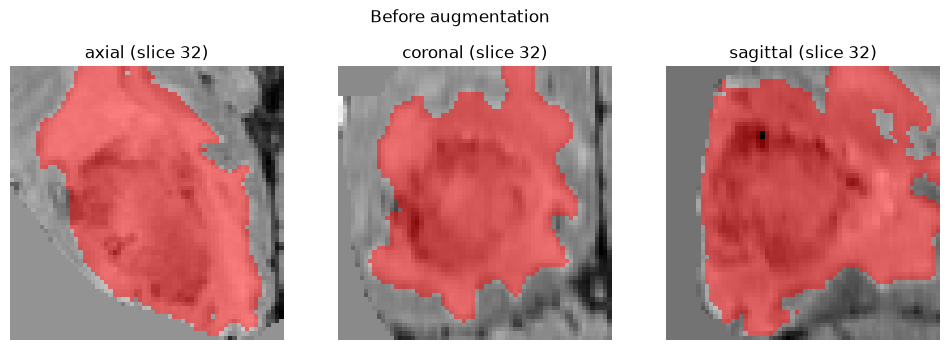

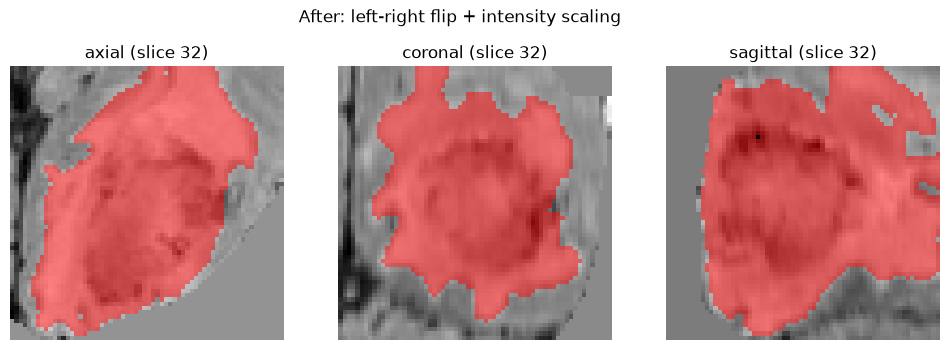

In [18]:
cached_image, cached_label = load_preprocessed_case(case_id)

# A 64^3 patch around the tumor centre
center = np.argwhere(cached_label > 0).mean(axis=0).astype(int)
x, y, z = np.clip(center - 32, 0, np.array(cached_label.shape) - 64)
patch_image = cached_image[:, x:x + 64, y:y + 64, z:z + 64].astype(np.float32)
patch_mask = cached_label[x:x + 64, y:y + 64, z:z + 64] > 0

# flip_chance=1 so the example always includes the flip
new_image, new_mask = augment(patch_image, patch_mask, np.random.default_rng(SEED), flip_chance=1)

point = center - [x, y, z]
save_figure(show_planes(patch_image[0], point, [(patch_mask, "red")], "Before augmentation"), "C_augment_before")
save_figure(show_planes(new_image[0], point, [(new_mask, "red")], "After: left-right flip + intensity scaling"),
            "C_augment_after")

- Left-right flip and ±10% intensity scaling: realistic and label-safe.
- Training only, so validation and test use real images.

## D. Patch-based volumetric training

### D.0 Data, batch check and model

In [19]:
# Training cases stay in memory (about 9 GB) because every step cuts patches from them.
# Validation cases are read one at a time inside validate().
train_cases = [load_preprocessed_case(case_id) for case_id in tqdm(ids_in_split("train"), desc="loading")]
val_ids = ids_in_split("validation")

images, masks = next(iter(DataLoader(PatchDataset(train_cases, "uniform", length=BATCH_SIZE), batch_size=BATCH_SIZE)))
print("images:", tuple(images.shape), images.dtype)
print("masks: ", tuple(masks.shape), masks.dtype, "values", masks.unique().tolist())

loading:   0%|          | 0/338 [00:00<?, ?it/s]

images: (8, 4, 64, 64, 64) torch.float32
masks:  (8, 1, 64, 64, 64) torch.float32 values [0.0, 1.0]


In [20]:
model = UNet3D()
print("input channels:  4 (FLAIR, T1w, T1gd, T2w)")
print("output channels: 1 (whole-tumor logit)")
print(f"parameters:      {sum(p.numel() for p in model.parameters()):,}")
print("patch size:     ", PATCH_SIZE)

input channels:  4 (FLAIR, T1w, T1gd, T2w)
output channels: 1 (whole-tumor logit)
parameters:      5,649,153
patch size:      (64, 64, 64)


### D.1 Uniform random patches

loss: BCE + soft Dice | optimizer: Adam, lr 0.0003 | seed: 42
budget: 30 epochs x 500 steps x 8 patches


uniform epoch 1:   0%|          | 0/500 [00:00<?, ?it/s]

epoch  1: train loss 1.107, val loss 0.959, val Dice 0.821, tumor patches 0.79


uniform epoch 2:   0%|          | 0/500 [00:00<?, ?it/s]

epoch  2: train loss 0.821, val loss 0.671, val Dice 0.840, tumor patches 0.78


...

epoch 28: train loss 0.305, val loss 0.189, val Dice 0.876, tumor patches 0.78


uniform epoch 29:   0%|          | 0/500 [00:00<?, ?it/s]

epoch 29: train loss 0.310, val loss 0.168, val Dice 0.880, tumor patches 0.78


uniform epoch 30:   0%|          | 0/500 [00:00<?, ?it/s]

epoch 30: train loss 0.336, val loss 0.343, val Dice 0.714, tumor patches 0.78


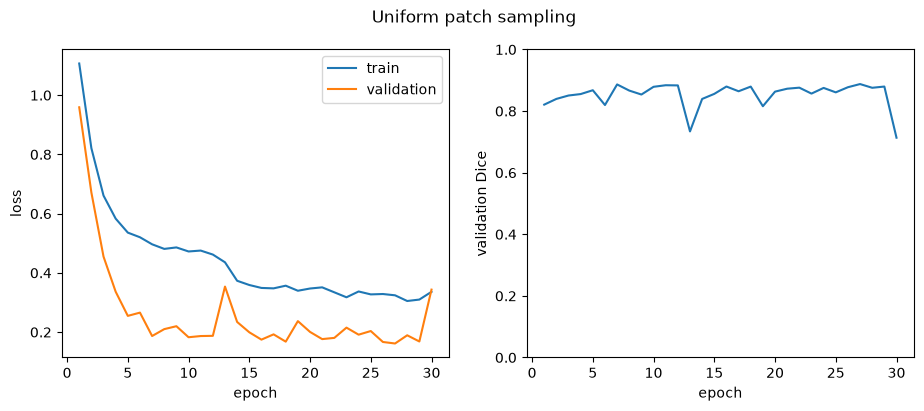

In [21]:
print(f"loss: BCE + soft Dice | optimizer: Adam, lr {LEARNING_RATE} | seed: {SEED}")
print(f"budget: {EPOCHS} epochs x {STEPS_PER_EPOCH} steps x {BATCH_SIZE} patches")

uniform_model, uniform_history = train_model("uniform", train_cases, val_ids)
save_figure(plot_training_curves(uniform_history, "Uniform patch sampling"), "D1_uniform_curves")

### D.2 Tumor-aware patches

tumor epoch 1:   0%|          | 0/500 [00:00<?, ?it/s]

epoch  1: train loss 0.921, val loss 0.994, val Dice 0.765, tumor patches 0.89


tumor epoch 2:   0%|          | 0/500 [00:00<?, ?it/s]

epoch  2: train loss 0.618, val loss 0.738, val Dice 0.807, tumor patches 0.90


tumor epoch 3:   0%|          | 0/500 [00:00<?, ?it/s]

...

tumor epoch 29:   0%|          | 0/500 [00:00<?, ?it/s]

epoch 29: train loss 0.258, val loss 0.159, val Dice 0.890, tumor patches 0.89


tumor epoch 30:   0%|          | 0/500 [00:00<?, ?it/s]

epoch 30: train loss 0.261, val loss 0.168, val Dice 0.888, tumor patches 0.89


,uniform,tumor-aware
fraction of patches with tumor,0.78415,0.89015


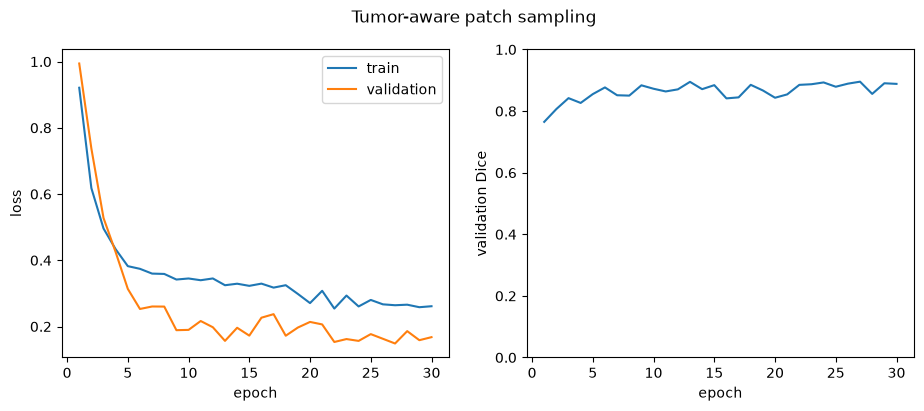

In [22]:
# Same model, seed, loss and budget as D.1; only the sampler changes
tumor_model, tumor_history = train_model("tumor", train_cases, val_ids)
save_figure(plot_training_curves(tumor_history, "Tumor-aware patch sampling"), "D2_tumor_curves")

# Fraction of training patches that contained tumor, averaged over all epochs
save_table(pd.DataFrame({"uniform": [uniform_history["tumor_patch_fraction"].mean()],
                         "tumor-aware": [tumor_history["tumor_patch_fraction"].mean()]},
                        index=["fraction of patches with tumor"]), "D_tumor_patch_fraction")

- No overfitting (validation loss does not rise).
- Unstable: single-epoch Dice drops, mostly in the uniform run.
- Slight underfitting: still improving at epoch 27.

## E. Controlled sampling comparison

In [23]:
# Best checkpoint of each run, evaluated on the full validation volumes
val_ids = ids_in_split("validation")
uniform_val = save_table(evaluate_model(load_model("uniform"), val_ids), "E_uniform_validation")
tumor_val = save_table(evaluate_model(load_model("tumor"), val_ids), "E_tumor_validation")

columns = ["dice", "sensitivity", "fp_volume_ml", "hd95_mm", "volume_error_ml"]
comparison = pd.DataFrame({"uniform": uniform_val[columns].mean(), "tumor-aware": tumor_val[columns].mean()})
save_table(comparison, "E_sampling_comparison")

evaluating:   0%|          | 0/73 [00:00<?, ?it/s]

evaluating:   0%|          | 0/73 [00:00<?, ?it/s]

,uniform,tumor-aware
dice,0.887785,0.895519
sensitivity,0.903426,0.897605
fp_volume_ml,10.598548,8.523384
hd95_mm,9.626086,9.174554
volume_error_ml,1.640151,-1.287370


In [24]:
# Final configuration: the higher mean validation Dice (validation data only)
final_sampling = "tumor" if tumor_val["dice"].mean() > uniform_val["dice"].mean() else "uniform"
final_val = tumor_val if final_sampling == "tumor" else uniform_val
print("final configuration:", final_sampling)

final configuration: tumor


- Tumor-aware wins: Dice 0.896 vs 0.888, fewer false positives. Small gap.
- Reason: more tumor-edge patches (89% vs 78%).
- Too much oversampling → too little normal brain → over-segmentation.

## F. Full-volume reconstruction and evaluation

### F.1 Sliding-window settings

In [25]:
stride = int(PATCH_SIZE[0] * (1 - OVERLAP))
print(f"patch size {PATCH_SIZE}, stride {stride} voxels, overlap {OVERLAP:.0%}")
print("blending: plain average of the overlapping probabilities, then threshold at", THRESHOLD)

patch size (64, 64, 64), stride 32 voxels, overlap 50%
blending: plain average of the overlapping probabilities, then threshold at 0.5


### F.2 Test results

In [26]:
# First and only use of the test labels
final_model = load_model(final_sampling)
test_ids = ids_in_split("test")
test_results = save_table(evaluate_model(final_model, test_ids), "F_test_results")

metrics = ["dice", "iou", "sensitivity", "hd95_mm"]
display(test_results[metrics].round(3))
display(test_results[metrics].agg(["mean", "std", "median"]))
print("empty predictions:", test_results["empty_prediction"].sum())

evaluating:   0%|          | 0/73 [00:00<?, ?it/s]

,dice,iou,sensitivity,hd95_mm
BRATS_002,0.909,0.833,0.972,3.162
BRATS_012,0.920,0.853,0.919,4.123
BRATS_016,0.917,0.847,0.947,3.162
BRATS_033,0.955,0.914,0.961,2.000
BRATS_039,0.855,0.747,0.756,4.472
BRATS_050,0.930,0.868,0.887,4.690
BRATS_059,0.919,0.850,0.861,3.606
BRATS_065,0.857,0.750,0.848,10.198
BRATS_067,0.944,0.893,0.923,2.000
BRATS_078,0.643,0.473,0.863,11.446


,dice,iou,sensitivity,hd95_mm
mean,0.899881,0.822257,0.895697,7.747852
std,0.055668,0.085913,0.065626,9.720546
median,0.916278,0.845491,0.914803,4.000000


empty predictions: 0


### F.3 Tumor volume

In [27]:
volumes = ["true_volume_ml", "pred_volume_ml", "volume_error_ml", "volume_error_pct"]
display(test_results[volumes].round(2))
print(f"mean absolute volume error: {test_results['volume_error_ml'].abs().mean():.2f} mL "
      f"({test_results['volume_error_pct'].abs().mean():.1f} %)")

,true_volume_ml,pred_volume_ml,volume_error_ml,volume_error_pct
BRATS_002,63.06,71.83,8.77,13.90
BRATS_012,21.61,21.56,-0.05,-0.24
BRATS_016,82.73,88.08,5.35,6.46
BRATS_033,114.02,115.46,1.45,1.27
BRATS_039,37.01,28.46,-8.56,-23.12
BRATS_050,76.24,69.31,-6.93,-9.08
BRATS_059,99.57,86.99,-12.58,-12.63
BRATS_065,166.09,162.34,-3.75,-2.26
BRATS_067,55.28,52.89,-2.39,-4.32
BRATS_078,85.08,143.43,58.35,68.58


mean absolute volume error: 10.50 mL (10.9 %)


### F.4 Connected-component postprocessing

In [28]:
# Rule: keep only the largest connected tumor region, to remove small false-positive islands.
# Whether to keep the rule is decided on the validation set, not on the test set.
val_post = evaluate_model(final_model, val_ids, postprocess=True)
use_postprocessing = val_post["dice"].mean() > final_val["dice"].mean()
print(f"validation Dice: {final_val['dice'].mean():.4f} without, {val_post['dice'].mean():.4f} with the rule")
print("keep the rule:", use_postprocessing)

# Test results before and after the rule, reported either way
test_post = save_table(evaluate_model(final_model, test_ids, postprocess=True), "F_test_results_postprocessed")
columns = metrics + ["fp_volume_ml", "volume_error_ml"]
save_table(pd.DataFrame({"before": test_results[columns].mean(), "after": test_post[columns].mean()}),
           "F_postprocessing_effect")

evaluating:   0%|          | 0/73 [00:00<?, ?it/s]

validation Dice: 0.8955 without, 0.8821 with the rule
keep the rule: False


evaluating:   0%|          | 0/73 [00:00<?, ?it/s]

,before,after
dice,0.899881,0.902139
iou,0.822257,0.825847
sensitivity,0.895697,0.890627
hd95_mm,7.747852,8.662049
fp_volume_ml,8.694548,7.630329
volume_error_ml,-1.973466,-3.558576


Rule: keep the largest component (a glioma is usually one region). Validation Dice fell (0.8955 → 0.8821), so **not kept**.

## G. Three-plane error analysis and limitations

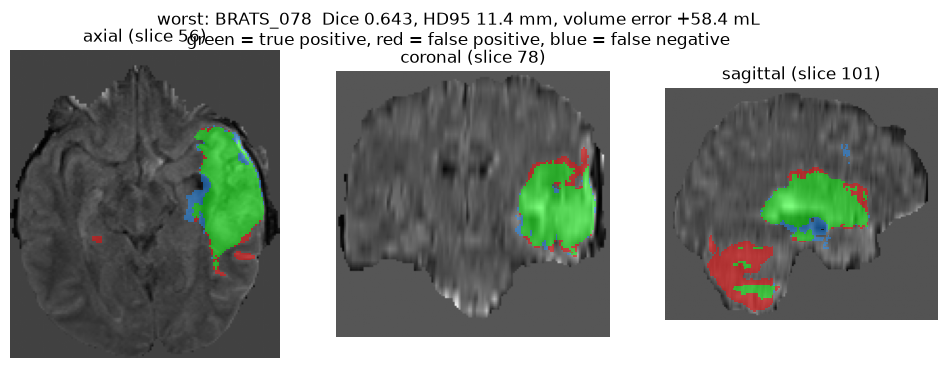

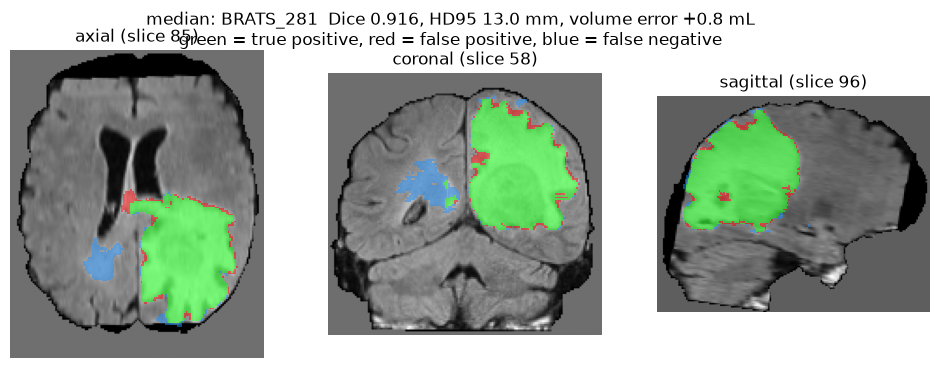

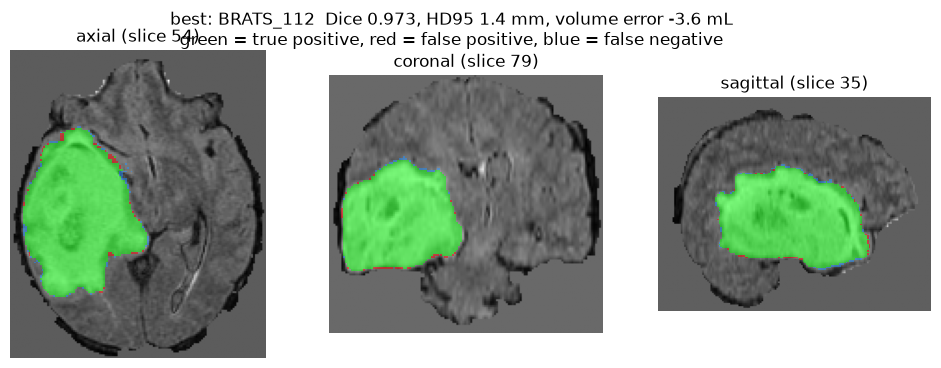

In [29]:
final_test = test_post if use_postprocessing else test_results
ranked = final_test.sort_values("dice")
chosen = {"worst": ranked.index[0], "median": ranked.index[len(ranked) // 2], "best": ranked.index[-1]}

for name, case_id in chosen.items():
    image, label = load_preprocessed_case(case_id)
    prediction = predict_mask(final_model, image, use_postprocessing)
    target = label > 0
    row = final_test.loc[case_id]

    # Slices through the centre of the reference tumor
    point = np.argwhere(target).mean(axis=0).astype(int)
    title = (f"{name}: {case_id}  Dice {row.dice:.3f}, HD95 {row.hd95_mm:.1f} mm, "
             f"volume error {row.volume_error_ml:+.1f} mL\ngreen = true positive, red = false positive, "
             f"blue = false negative")
    save_figure(show_planes(image[0].astype(np.float32), point, error_overlays(prediction, target), title),
                f"G_{name}_{case_id}")

In [30]:
# Dice, HD95 and volume error side by side for the three cases
save_table(final_test.loc[list(chosen.values()), ["dice", "hd95_mm", "volume_error_ml", "volume_error_pct"]],
           "G_best_median_worst")

,dice,hd95_mm,volume_error_ml,volume_error_pct
BRATS_078,0.642563,11.445523,58.350003,68.580092
BRATS_281,0.916278,13.038405,0.761000,0.437537
BRATS_112,0.973037,1.414214,-3.649000,-2.156811


- **Best:** thin border errors. **Median:** missed faint region across the midline (patch context). **Worst:** large false-positive region.
- Median case: good Dice but HD95 13 mm, and volume error ≈ 0 because errors cancel. One metric is not enough.
- **Limitations:** small budget, no external site, reference labels, whole tumor only, one duplicate case.

## Bonus 1. Missing-modality stress test

In [31]:
# Same final model, no retraining. Each channel in turn is replaced with zeros at test time.
# After normalisation 0 is the brain-average intensity, so the channel carries no information.
columns = ["dice", "hd95_mm", "volume_error_ml"]
rows = {"all four channels": final_test[columns].mean()}
for channel, name in enumerate(MODALITIES):
    results = evaluate_model(final_model, test_ids, use_postprocessing, zero_channel=channel)
    rows[f"{name} zeroed"] = results[columns].mean()

missing_modality = pd.DataFrame(rows).T
missing_modality["dice_drop"] = missing_modality.loc["all four channels", "dice"] - missing_modality["dice"]
save_table(missing_modality, "Bonus1_missing_modality")

evaluating:   0%|          | 0/73 [00:00<?, ?it/s]

evaluating:   0%|          | 0/73 [00:00<?, ?it/s]

evaluating:   0%|          | 0/73 [00:00<?, ?it/s]

evaluating:   0%|          | 0/73 [00:00<?, ?it/s]

,dice,hd95_mm,volume_error_ml,dice_drop
all four channels,0.899881,7.747852,-1.973466,0.000000
FLAIR zeroed,0.413499,24.269682,-70.048538,0.486382
T1w zeroed,0.848840,26.234551,20.083412,0.051041
T1gd zeroed,0.887517,7.845199,-6.255055,0.012364
T2w zeroed,0.876811,10.473612,-2.982480,0.023070


- FLAIR matters most (Dice 0.900 → 0.413 when zeroed).
- Zero = flat image never seen in training, unlike a real missing scan.
- Fix: random channel dropout during training.

## Bonus 2. Sliding-window seam test

In [32]:
# Same final model on the test set with 0 %, 25 % and 50 % overlap
rows = {}
for overlap in [0.0, 0.25, 0.5]:
    start_time = time.time()
    results = evaluate_model(final_model, test_ids, use_postprocessing, overlap=overlap)
    rows[f"{overlap:.0%}"] = {**results[["dice", "hd95_mm", "volume_error_ml"]].mean(),
                              "minutes": (time.time() - start_time) / 60}
save_table(pd.DataFrame(rows).T, "Bonus2_overlap")

evaluating:   0%|          | 0/73 [00:00<?, ?it/s]

evaluating:   0%|          | 0/73 [00:00<?, ?it/s]

evaluating:   0%|          | 0/73 [00:00<?, ?it/s]

,dice,hd95_mm,volume_error_ml,minutes
0%,0.889127,9.330157,-1.627959,0.936725
25%,0.898127,7.350321,-2.063493,1.011453
50%,0.899881,7.747852,-1.973466,1.423569


mean difference near borders: 0.0061, elsewhere: 0.0018


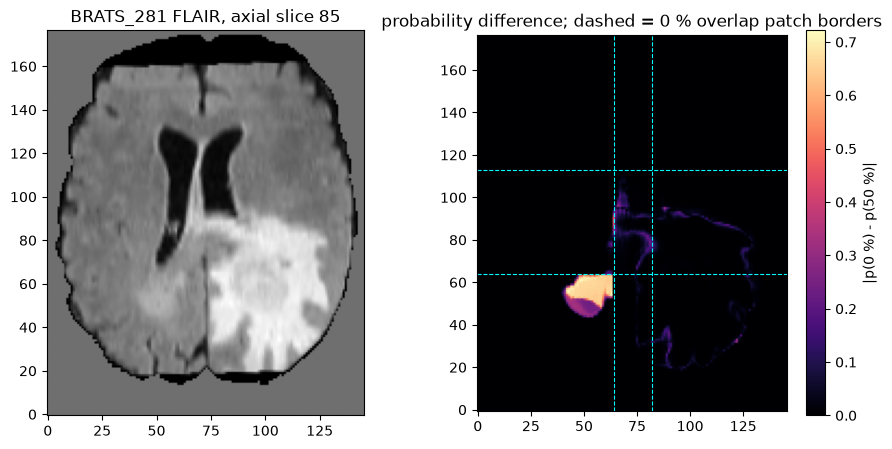

In [33]:
# Probability difference between 0 % and 50 % overlap on the median test case.
# With 0 % overlap the patches touch at multiples of 64 voxels, which is where seams appear.
image, label = load_preprocessed_case(chosen["median"])
no_overlap = predict_volume(final_model, image, overlap=0.0).cpu().numpy()
half_overlap = predict_volume(final_model, image, overlap=0.5).cpu().numpy()
difference = np.abs(no_overlap - half_overlap)

z = int(np.argwhere(label > 0).mean(axis=0)[2])
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(get_plane_slice(image[0].astype(np.float32), "axial", z), cmap="gray", origin="lower")
axes[0].set_title(f"{chosen['median']} FLAIR, axial slice {z}")
shown = axes[1].imshow(get_plane_slice(difference, "axial", z), cmap="magma", origin="lower")
fig.colorbar(shown, ax=axes[1], label="|p(0 %) - p(50 %)|")
axes[1].set_title("probability difference; dashed = 0 % overlap patch borders")
for x in patch_starts(difference.shape[0], 64, 0.0)[1:]:
    axes[1].axvline(x, color="cyan", linestyle="--", linewidth=0.8)
for y in patch_starts(difference.shape[1], 64, 0.0)[1:]:
    axes[1].axhline(y, color="cyan", linestyle="--", linewidth=0.8)
save_figure(fig, "Bonus2_seam_difference")

# Mean difference within 3 voxels of a 0 % overlap patch border compared with everywhere else
near_border = np.zeros(difference.shape, dtype=bool)
for axis in range(3):
    for border in patch_starts(difference.shape[axis], 64, 0.0)[1:]:
        index = [slice(None)] * 3
        index[axis] = slice(border - 3, border + 3)
        near_border[tuple(index)] = True
print(f"mean difference near borders: {difference[near_border].mean():.4f}, "
      f"elsewhere: {difference[~near_border].mean():.4f}")

- Overlap removes seams at patch borders; 25% gives most of the gain, 50% is slower.
- Choosing overlap on test labels biases the result; use validation.